# Self-Learning Lab Program 1: Gradient Descent & MLP Optimizers

**Dataset:** Fashion-MNIST (small subset)  
**Framework:** TensorFlow / Keras  
**Goal:** Compare batch, stochastic and mini-batch gradient descent; optimizers and learning-rate schedules; regularization; early stopping; and plain vs residual MLPs.

> Run in Google Colab. Select **Runtime → Change runtime type → T4 GPU** if available. The notebook is designed to run on a small subset so the experiments finish faster.

## 1. Setup and imports

This notebook uses a fixed random seed so comparisons are more repeatable. All models use the same Fashion-MNIST subset and the same train/validation/test split.

In [1]:
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


## 2. Load and prepare a subset of Fashion-MNIST

Fashion-MNIST contains 28×28 grayscale clothing images in 10 classes. We use a stratified subset: 10,000 training images, 2,000 validation images and 2,000 test images.

In [2]:
from sklearn.model_selection import train_test_split

(x_all, y_all), (x_test_all, y_test_all) = keras.datasets.fashion_mnist.load_data()

# Scale pixels from [0, 255] to [0, 1]
x_all = x_all.astype("float32") / 255.0
x_test_all = x_test_all.astype("float32") / 255.0

# Stratified training subset
x_subset, _, y_subset, _ = train_test_split(
    x_all, y_all, train_size=10000, stratify=y_all, random_state=SEED
)
x_train, x_val, y_train, y_val = train_test_split(
    x_subset, y_subset, test_size=0.20, stratify=y_subset, random_state=SEED
)

# Stratified test subset
x_test, _, y_test, _ = train_test_split(
    x_test_all, y_test_all, train_size=2000, stratify=y_test_all, random_state=SEED
)

print("Train:", x_train.shape, "Validation:", x_val.shape, "Test:", x_test.shape)
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Train: (8000, 28, 28) Validation: (2000, 28, 28) Test: (2000, 28, 28)


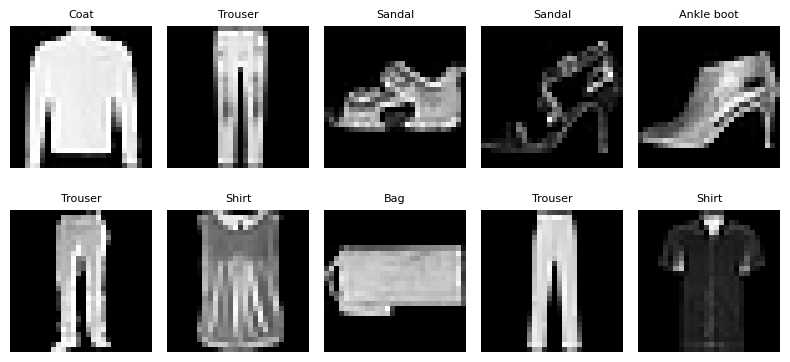

In [3]:
# Display a few examples
plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]], fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Demonstrate batch, stochastic and mini-batch gradient descent

We use a small synthetic binary-classification dataset and the same simple neural network for all three methods.

- **Batch GD:** one update after processing the entire training set.
- **Stochastic GD (SGD):** one update for each training example.
- **Mini-batch GD:** one update after processing a small group of examples (here, 32).

The number of updates per epoch differs: batch = 1, stochastic = number of examples, mini-batch = approximately N/32.

Batch GD: 1 parameter update(s) per epoch
Stochastic GD: 600 parameter update(s) per epoch
Mini-batch GD (32): 19 parameter update(s) per epoch


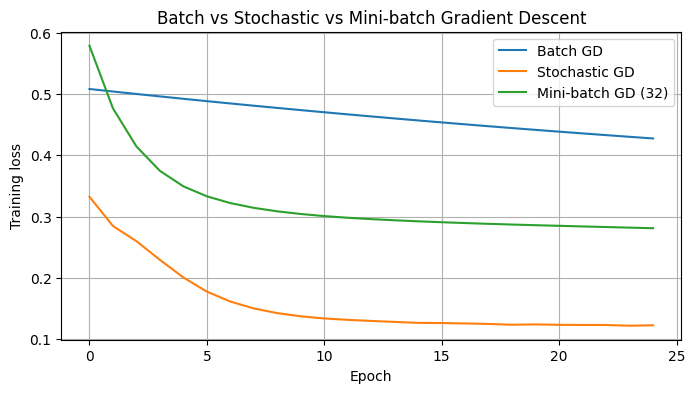

In [4]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

X_demo, y_demo = make_moons(n_samples=600, noise=0.20, random_state=SEED)
X_demo = StandardScaler().fit_transform(X_demo).astype("float32")
y_demo = y_demo.astype("float32")

def make_demo_model():
    model = keras.Sequential([
        layers.Input(shape=(2,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    return model

def run_gd_demo(batch_size, label, epochs=25):
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    model = make_demo_model()
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.05),
                  loss="binary_crossentropy", metrics=["accuracy"])
    history = model.fit(X_demo, y_demo, batch_size=batch_size,
                        epochs=epochs, verbose=0)
    updates_per_epoch = int(np.ceil(len(X_demo) / batch_size))
    return history, updates_per_epoch

gd_results = {}
for label, bs in [("Batch GD", len(X_demo)),
                  ("Stochastic GD", 1),
                  ("Mini-batch GD (32)", 32)]:
    hist, updates = run_gd_demo(bs, label)
    gd_results[label] = hist
    print(f"{label}: {updates} parameter update(s) per epoch")

plt.figure(figsize=(8, 4))
for label, hist in gd_results.items():
    plt.plot(hist.history["loss"], label=label)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Batch vs Stochastic vs Mini-batch Gradient Descent")
plt.legend()
plt.grid(True)
plt.show()

## 4. MLP model and optimizer experiments

We compare selected momentum-based and adaptive optimizers:

- **SGD with momentum**
- **Adam**
- **RMSprop**

Each optimizer is tested with a constant learning rate and a scheduled learning rate. For a fair comparison, the architecture, subset, batch size and maximum epochs are kept the same.

In [5]:
def build_mlp(dropout_rate=0.0, l2_strength=0.0, residual=False):
    inputs = keras.Input(shape=(28, 28))
    x = layers.Flatten()(inputs)
    x = layers.Dense(256, activation="relu",
                     kernel_regularizer=regularizers.l2(l2_strength) if l2_strength else None)(x)
    if dropout_rate:
        x = layers.Dropout(dropout_rate)(x)

    if residual:
        # Project to 128 units, then add a same-sized residual branch
        x = layers.Dense(128, activation="relu")(x)
        shortcut = x
        h = layers.Dense(128, activation="relu")(x)
        h = layers.Dense(128)(h)
        x = layers.Add()([shortcut, h])
        x = layers.Activation("relu")(x)
    else:
        x = layers.Dense(128, activation="relu")(x)

    if dropout_rate:
        x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs)

def make_optimizer(name, lr):
    if name == "SGD+Momentum":
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9)
    if name == "Adam":
        return keras.optimizers.Adam(learning_rate=lr)
    if name == "RMSprop":
        return keras.optimizers.RMSprop(learning_rate=lr, momentum=0.0)
    raise ValueError(name)

def make_schedule(kind, initial_lr):
    if kind == "constant":
        return initial_lr
    if kind == "exponential":
        return keras.optimizers.schedules.ExponentialDecay(
            initial_learning_rate=initial_lr, decay_steps=500,
            decay_rate=0.90, staircase=True
        )
    raise ValueError(kind)

def train_optimizer_experiment(opt_name, lr_kind, epochs=8):
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    lr = 0.01 if opt_name == "SGD+Momentum" else 0.001
    optimizer = make_optimizer(opt_name, make_schedule(lr_kind, lr))
    model = build_mlp()
    model.compile(optimizer=optimizer,
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    start = time.time()
    hist = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                     epochs=epochs, batch_size=128, verbose=0)
    elapsed = time.time() - start
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    return model, hist, {"optimizer": opt_name, "lr": lr_kind,
                         "test_accuracy": test_acc, "test_loss": test_loss,
                         "seconds": elapsed}

optimizer_results = []
optimizer_histories = {}
for opt_name in ["SGD+Momentum", "Adam", "RMSprop"]:
    for lr_kind in ["constant", "exponential"]:
        model, hist, row = train_optimizer_experiment(opt_name, lr_kind)
        optimizer_results.append(row)
        optimizer_histories[(opt_name, lr_kind)] = hist

optimizer_df = pd.DataFrame(optimizer_results).sort_values("test_accuracy", ascending=False)
display(optimizer_df)

,optimizer,lr,test_accuracy,test_loss,seconds
2,Adam,constant,0.8525,0.423741,7.704395
3,Adam,exponential,0.8420,0.441124,6.121986
5,RMSprop,exponential,0.8345,0.466724,5.789224
0,SGD+Momentum,constant,0.8320,0.463253,7.462449
1,SGD+Momentum,exponential,0.8300,0.466947,5.369808
4,RMSprop,constant,0.8200,0.470672,7.156211


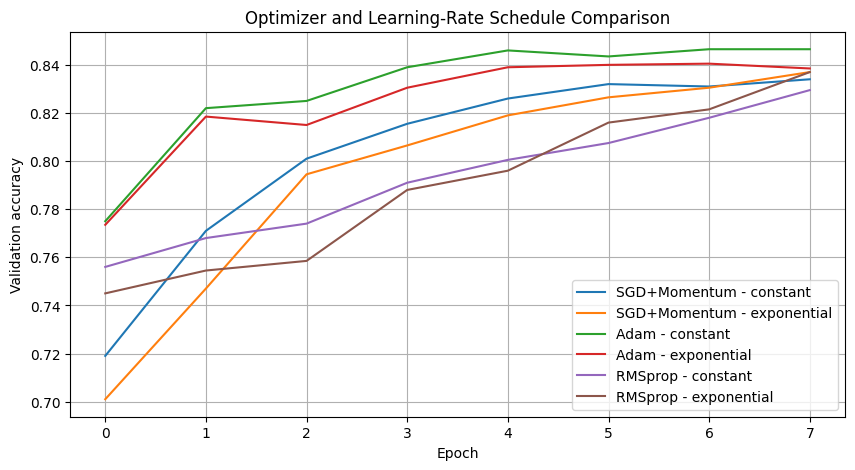

In [6]:
# Plot validation accuracy for all six optimizer/LR combinations
plt.figure(figsize=(10, 5))
for key, hist in optimizer_histories.items():
    plt.plot(hist.history["val_accuracy"], label=f"{key[0]} - {key[1]}")
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy")
plt.title("Optimizer and Learning-Rate Schedule Comparison")
plt.legend()
plt.grid(True)
plt.show()

## 5. Investigate overfitting

Overfitting occurs when training performance keeps improving but validation performance stops improving or becomes worse. We train a larger MLP for more epochs and compare training and validation accuracy/loss.

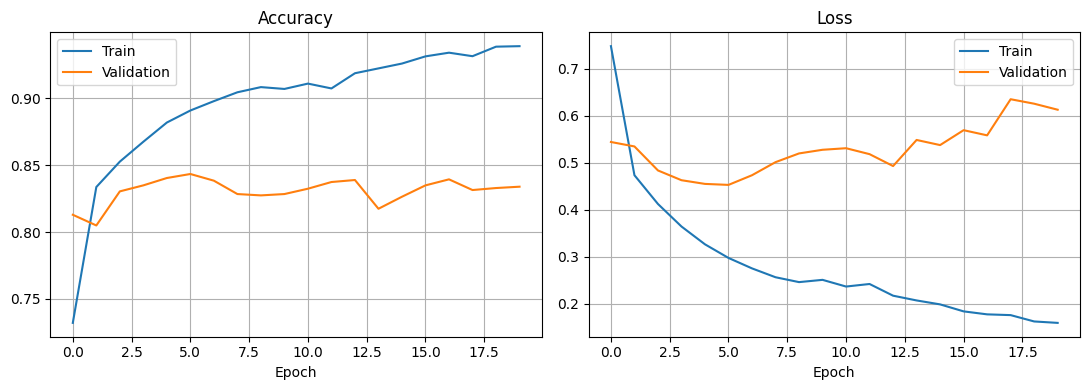

In [7]:
tf.keras.backend.clear_session()
overfit_model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dense(512, activation="relu"),
    layers.Dense(10, activation="softmax")
])
overfit_model.compile(optimizer="adam",
                      loss="sparse_categorical_crossentropy",
                      metrics=["accuracy"])
overfit_history = overfit_model.fit(
    x_train, y_train, validation_data=(x_val, y_val),
    epochs=20, batch_size=128, verbose=0
)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(overfit_history.history["accuracy"], label="Train")
ax[0].plot(overfit_history.history["val_accuracy"], label="Validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(True)
ax[1].plot(overfit_history.history["loss"], label="Train")
ax[1].plot(overfit_history.history["val_loss"], label="Validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(True)
plt.tight_layout()
plt.show()

## 6. Evaluate dropout, L2 regularization and data augmentation

We compare a baseline MLP with:
1. Dropout
2. L2 weight regularization
3. Data augmentation (small translations and rotations)

The same train/validation/test subsets, optimizer, batch size and epoch limit are used. The augmentation layer is active only during training.

In [8]:
def build_regularized_model(mode):
    inputs = keras.Input(shape=(28, 28))
    x = inputs
    if mode == "augmentation":
        x = layers.RandomTranslation(0.08, 0.08)(x)
        x = layers.RandomRotation(0.05)(x)
    x = layers.Flatten()(x)
    reg = regularizers.l2(1e-4) if mode == "l2" else None
    x = layers.Dense(256, activation="relu", kernel_regularizer=reg)(x)
    if mode == "dropout":
        x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=reg)(x)
    if mode == "dropout":
        x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs)

regularization_results = []
regularization_histories = {}
for mode in ["baseline", "dropout", "l2", "augmentation"]:
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    model = build_regularized_model(mode)
    model.compile(optimizer=keras.optimizers.Adam(0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                     epochs=12, batch_size=128, verbose=0)
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    regularization_histories[mode] = hist
    regularization_results.append({
        "method": mode, "best_val_accuracy": max(hist.history["val_accuracy"]),
        "test_accuracy": test_acc, "test_loss": test_loss
    })

regularization_df = pd.DataFrame(regularization_results).sort_values("test_accuracy", ascending=False)
display(regularization_df)

,method,best_val_accuracy,test_accuracy,test_loss
2,l2,0.8445,0.8545,0.483563
1,dropout,0.8435,0.8505,0.427392
0,baseline,0.8415,0.8365,0.478629
3,augmentation,0.4470,0.3940,2.049908


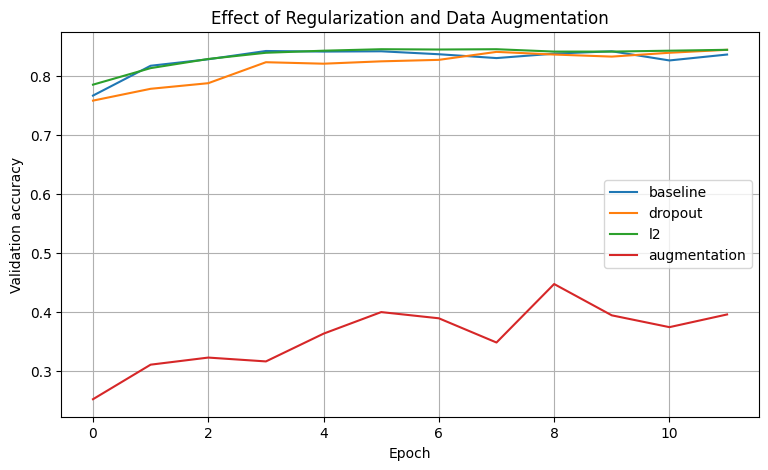

In [9]:
plt.figure(figsize=(9, 5))
for mode, hist in regularization_histories.items():
    plt.plot(hist.history["val_accuracy"], label=mode)
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy")
plt.title("Effect of Regularization and Data Augmentation")
plt.legend(); plt.grid(True); plt.show()

## 7. Apply early stopping

Early stopping monitors validation loss. If it does not improve for 3 consecutive epochs, training stops and the best weights are restored.

In [10]:
tf.keras.backend.clear_session()
tf.random.set_seed(SEED)
early_model = build_mlp()
early_model.compile(optimizer="adam",
                    loss="sparse_categorical_crossentropy",
                    metrics=["accuracy"])
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)
early_history = early_model.fit(
    x_train, y_train, validation_data=(x_val, y_val),
    epochs=30, batch_size=128, callbacks=[early_stop], verbose=1
)
print("Epochs actually run:", len(early_history.history["loss"]))
print("Best validation loss:", min(early_history.history["val_loss"]))
print("Test evaluation:", early_model.evaluate(x_test, y_test, verbose=0))

Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.7197 - loss: 0.8109 - val_accuracy: 0.7825 - val_loss: 0.6023
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8167 - loss: 0.5142 - val_accuracy: 0.8070 - val_loss: 0.5370
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8482 - loss: 0.4422 - val_accuracy: 0.8210 - val_loss: 0.4924
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8614 - loss: 0.3986 - val_accuracy: 0.8300 - val_loss: 0.4727
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8704 - loss: 0.3679 - val_accuracy: 0.8410 - val_loss: 0.4577
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8785 - loss: 0.3446 - val_accuracy: 0.8445 - val_loss: 0.4536
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8856 - loss: 0.3205 - val_accuracy: 0.8375 - val_loss: 0.4616
Epoch 8/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8923 - loss: 0.3016 - val_accuracy: 0.8430 - v

## 8. Compare plain and residual MLPs under controlled conditions

Both models use the same data, optimizer, learning rate, batch size and epoch limit. The residual MLP includes a skip connection that adds the input of a block to its transformed output.

In [11]:
architecture_results = []
architecture_histories = {}

for residual_flag, label in [(False, "Plain MLP"), (True, "Residual MLP")]:
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    model = build_mlp(residual=residual_flag)
    model.compile(optimizer=keras.optimizers.Adam(0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist = model.fit(x_train, y_train, validation_data=(x_val, y_val),
                     epochs=10, batch_size=128, verbose=0)
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    architecture_histories[label] = hist
    architecture_results.append({
        "architecture": label,
        "parameters": model.count_params(),
        "best_val_accuracy": max(hist.history["val_accuracy"]),
        "test_accuracy": test_acc,
        "test_loss": test_loss
    })

architecture_df = pd.DataFrame(architecture_results)
display(architecture_df)

,architecture,parameters,best_val_accuracy,test_accuracy,test_loss
0,Plain MLP,235146,0.835,0.8375,0.446789
1,Residual MLP,268170,0.839,0.8405,0.445744


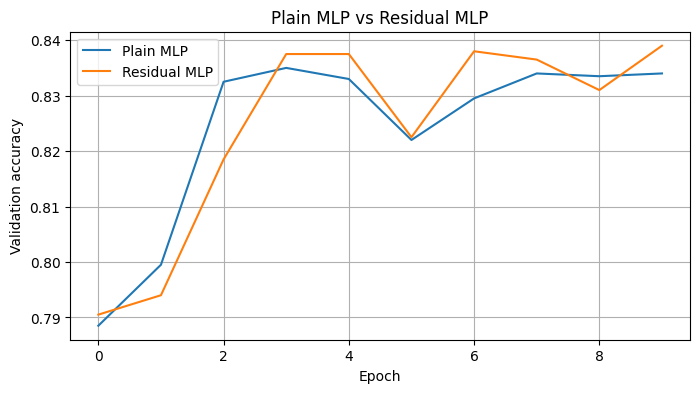

In [12]:
plt.figure(figsize=(8, 4))
for label, hist in architecture_histories.items():
    plt.plot(hist.history["val_accuracy"], label=label)
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy")
plt.title("Plain MLP vs Residual MLP")
plt.legend(); plt.grid(True); plt.show()

## 9. Final observations and conclusion

After running all cells, use the result tables and plots to write your observations.

**Points to discuss:**
1. Batch GD makes one update per epoch; stochastic GD makes one update per example; mini-batch GD makes updates per small group.
2. Momentum can smooth updates and accelerate learning in useful directions.
3. Adaptive optimizers such as Adam and RMSprop adjust effective learning rates for parameters.
4. A learning-rate schedule reduces the learning rate during training and may improve convergence.
5. Overfitting is indicated by a widening gap between training and validation performance.
6. Dropout, L2 regularization and data augmentation are techniques that may improve generalization; their effectiveness should be judged using validation/test results.
7. Early stopping prevents unnecessary training and restores the best validation weights.
8. Residual connections provide a shortcut path; they do not guarantee higher accuracy on every small experiment.

